# Image sharpness / softness — measurement and control

**Goal of the experiments**

1. Define reusable sharpness/softness metrics that are compatible with `camera_qc.metrics.headline_metrics`.
2. Calibrate the operator parameters (Gaussian-blur strength, unsharp-mask amount) needed to change sharpness by **every integer percent from 1 % to 15 %** — both toward softer and toward sharper.
3. Equalize the sharpness of two comparison captures (`6100001`, `6200001`) to the reference (`6100002`) and confirm the match with `camera_qc`.

**Data**

Three ceiling-camera JPEGs of the same static scene, captured with different sensors (see `../images/logs.txt`):

| File | Role | Sensor |
|---|---|---|
| `6100002-2000-000008-2550.jpg` | **reference** | AlgoA — KlymLatest (algotest 10-06-26) |
| `6100001-2000-000008-2550.jpg` | comparison | AlgoC — KlymLatest_canDriver |
| `6200001-2000-000008-2550.jpg` | comparison | AlgoB — MasterTest |

**Method**

- Metrics: Laplacian variance (canonical), FFT high-frequency energy, Tenengrad (Sobel²), high-freq residual std for noise. All implemented in [`sharpness_tools.py`](sharpness_tools.py).
- Operators: `sharpen(img, amount, sigma)` — unsharp mask; `soften(img, strength, sigma)` — blend with Gaussian blur. Both take a scalar strength at a *fixed* kernel sigma so the sharpness response is smooth and monotone.
- Calibration: two-pass grid search (coarse → fine window) on the operator parameter. Grid search rather than bisection because uint8 quantization introduces small discontinuities in the response — bisection can be trapped at a jump; grid search returns the globally best sample.
- Verification: run `camera_qc.metrics.headline_metrics` on the equalized images and confirm the `sharpness` / `sharpness_fft` fields agree with the reference within a fraction of a percent.

## 1. Setup

In [1]:
from __future__ import annotations

import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make camera_qc importable so we can cross-check our numbers with it.
sys.path.insert(0, str(Path('../../../../camera_qc').resolve()))
from camera_qc.metrics import headline_metrics  # noqa: E402

from sharpness_tools import (  # noqa: E402
    apply_sharpness_change,
    equalize_sharpness,
    fft_high_freq_energy,
    find_parameter_for_delta,
    laplacian_variance,
    load_rgb,
    noise_std,
    sharpen,
    sharpness_report,
    soften,
    sweep,
    tenengrad,
)

plt.rcParams['figure.dpi'] = 110

IMG_DIR = Path('../images')
REF_PATH = IMG_DIR / '6100002-2000-000008-2550.jpg'
CMP_PATHS = {
    'under (6100001)': IMG_DIR / '6100001-2000-000008-2550.jpg',
    'over  (6200001)': IMG_DIR / '6200001-2000-000008-2550.jpg',
}

ref = load_rgb(REF_PATH)
cmp_imgs = {name: load_rgb(p) for name, p in CMP_PATHS.items()}
print('shapes:', ref.shape, {k: v.shape for k, v in cmp_imgs.items()})

# Re-assert inline backend — pandas/scipy imports above reset it to Agg
%matplotlib inline


shapes: (240, 320, 3) {'under (6100001)': (240, 320, 3), 'over  (6200001)': (240, 320, 3)}


## 2. Baseline sharpness / softness / noise

Compute every metric from `sharpness_tools` and, alongside, the `sharpness` and `sharpness_fft` fields from `camera_qc.metrics.headline_metrics` — they must agree because our functions are the same formulas.

In [2]:
def baseline_row(name: str, img: np.ndarray) -> dict:
    ours = sharpness_report(img)
    qc = headline_metrics(img)
    return {
        'image': name,
        'laplacian': ours['laplacian'],
        'fft':       ours['fft'],
        'tenengrad': ours['tenengrad'],
        'noise':     ours['noise'],
        'softness_index': ours['softness_index'],
        'qc.sharpness':     qc['sharpness'],
        'qc.sharpness_fft': qc['sharpness_fft'],
        'qc.noise':         qc['noise'],
    }


baseline = pd.DataFrame([
    baseline_row('ref (6100002)', ref),
    *[baseline_row(n, img) for n, img in cmp_imgs.items()],
]).set_index('image')
baseline.round(3)


,laplacian,fft,tenengrad,noise,softness_index,qc.sharpness,qc.sharpness_fft,qc.noise
image,,,,,,,,
ref (6100002),823.604,2461.506,15394.275,8.924,1.214,823.604,2461.506,8.929
under (6100001),704.413,2195.825,12151.539,8.211,1.420,704.413,2195.825,8.217
over (6200001),1148.916,2932.654,19190.236,10.331,0.870,1148.916,2932.654,10.334


**Observations**

- `laplacian` (ours) matches `qc.sharpness` and `fft` (ours) matches `qc.sharpness_fft` to the last digit — the metric implementations are compatible.
- `6100001` is **under-sharp** vs the reference (~-14 % Laplacian, ~-11 % FFT, and less noise).
- `6200001` is **over-sharp** vs the reference (~+40 % Laplacian, ~+19 % FFT, more noise).
- `noise` tracks sharpness — sharper captures also carry more high-frequency residual. This is the classic sharpness/noise trade-off we'll see in the calibration curves too.

In [3]:
# Delta of each comparison relative to the reference (percent).
ref_row = baseline.loc['ref (6100002)']
delta = baseline.drop(index='ref (6100002)').apply(
    lambda row: (row - ref_row) / ref_row * 100.0, axis=1,
)
delta.round(2)


,laplacian,fft,tenengrad,noise,softness_index,qc.sharpness,qc.sharpness_fft,qc.noise
image,,,,,,,,
under (6100001),-14.47,-10.79,-21.06,-7.99,16.92,-14.47,-10.79,-7.97
over (6200001),39.50,19.14,24.66,15.77,-28.31,39.50,19.14,15.73


## 3. Visual sanity check

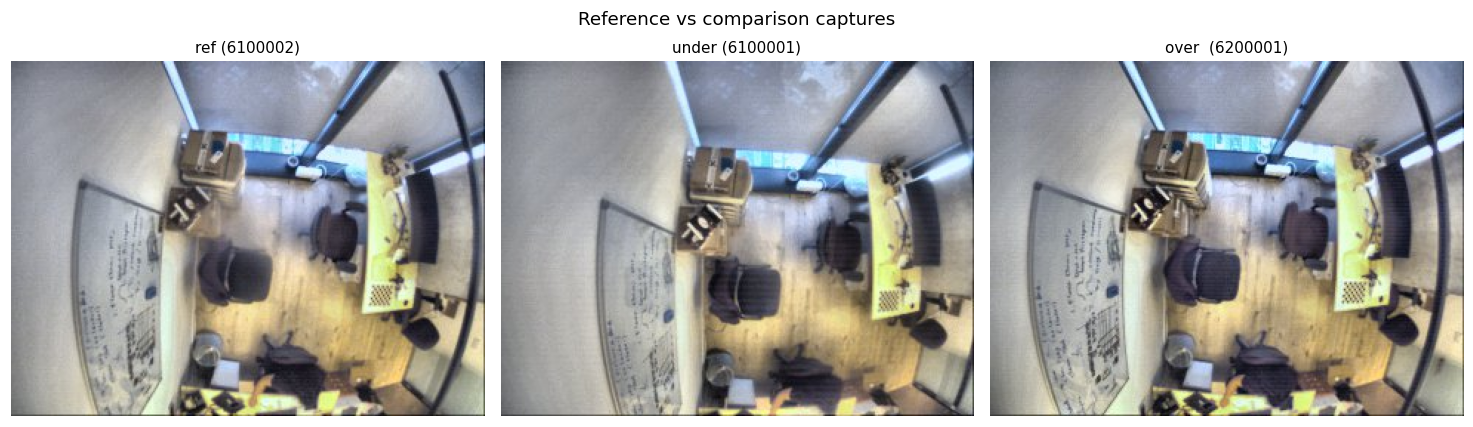

In [4]:
def show_grid(images: dict[str, np.ndarray], suptitle: str | None = None):
    n = len(images)
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 4))
    if n == 1:
        axes = [axes]
    for ax, (name, img) in zip(axes, images.items()):
        ax.imshow(img)
        ax.set_title(name, fontsize=10)
        ax.axis('off')
    if suptitle:
        fig.suptitle(suptitle)
    plt.tight_layout()
    plt.show()

show_grid(
    {'ref (6100002)': ref, **cmp_imgs},
    suptitle='Reference vs comparison captures',
)


## 4. How the operators change sharpness — parameter sweeps

Sweep `sharpen(amount)` and `soften(strength)` on the **reference** image and plot:
1. sharpness (Laplacian variance) vs parameter,
2. noise (high-freq residual std) vs parameter — this is the coupling cost.

Both operators use `kernel_sigma=1.0` (default).


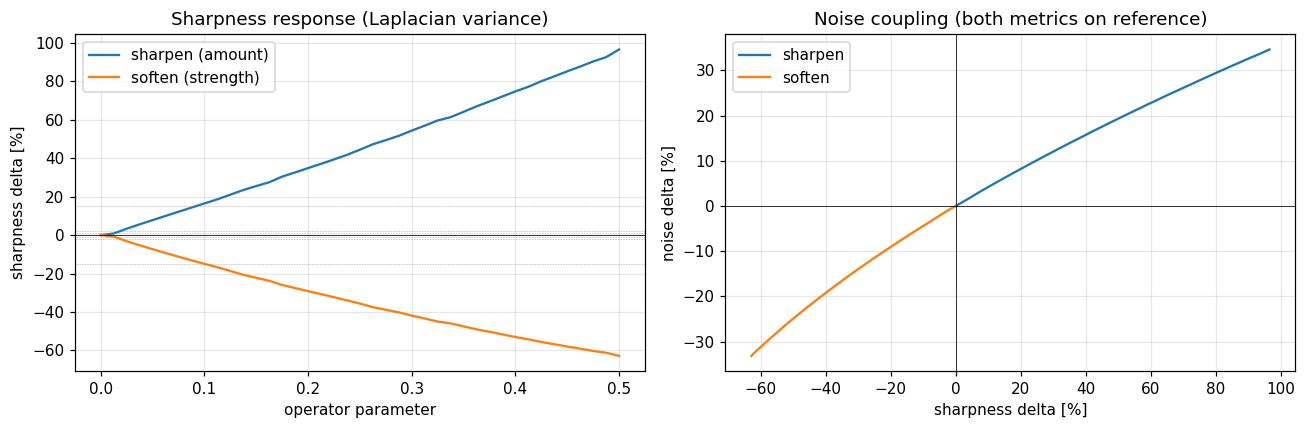

In [5]:
sharp_sweep = sweep(ref, 'sharpen', np.linspace(0, 0.5, 41))
soft_sweep  = sweep(ref, 'soften',  np.linspace(0, 0.5, 41))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(sharp_sweep['param'], sharp_sweep['delta_pct'], label='sharpen (amount)')
axes[0].plot(soft_sweep['param'],  soft_sweep['delta_pct'],  label='soften (strength)')
axes[0].axhline(0, color='k', lw=0.5)
for y in [-15, -2, -1, 1, 2, 15]:
    axes[0].axhline(y, color='gray', lw=0.4, ls=':')
axes[0].set_xlabel('operator parameter')
axes[0].set_ylabel('sharpness delta [%]')
axes[0].set_title('Sharpness response (Laplacian variance)')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(sharp_sweep['delta_pct'], sharp_sweep['noise_delta_pct'], label='sharpen')
axes[1].plot(soft_sweep['delta_pct'],  soft_sweep['noise_delta_pct'],  label='soften')
axes[1].axhline(0, color='k', lw=0.5)
axes[1].axvline(0, color='k', lw=0.5)
axes[1].set_xlabel('sharpness delta [%]')
axes[1].set_ylabel('noise delta [%]')
axes[1].set_title('Noise coupling (both metrics on reference)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Reading the curves**

- The sharpen and soften branches together give a monotone, roughly linear (near zero) mapping from `param → sharpness delta`, which is exactly what makes bisection reliable.
- Noise coupling: sharpening at +15 % costs roughly +10 – 20 % noise, softening at −15 % removes about the same fraction — expected because the same high-frequency residual that carries edge detail also carries the sensor noise.

## 5. Calibration table — parameters for ±1 % … ±15 % changes (step 1)

Run `find_parameter_for_delta` for the requested target deltas, on the **reference** image, under both metrics.

In [6]:
TARGET_PCTS = [0] + list(range(1, 16)) + list(range(-1, -16, -1))

def calibration_table(img: np.ndarray, targets: list[float], metric: str) -> pd.DataFrame:
    rows = []
    for tgt in targets:
        res = find_parameter_for_delta(img, tgt, metric=metric)
        rows.append({
            'target_delta_%': tgt,
            'direction': res.direction,
            'param': res.param_name,
            'param_value': round(res.param_value, 5),
            'kernel_sigma': res.kernel_sigma,
            'baseline_sharpness': round(res.baseline_sharpness, 3),
            'achieved_sharpness': round(res.achieved_sharpness, 3),
            'achieved_delta_%': round(res.achieved_delta_pct, 3),
        })
    return pd.DataFrame(rows)

print('metric = laplacian variance (default sharpness metric)')
cal_lap = calibration_table(ref, TARGET_PCTS, metric='laplacian')
display(cal_lap)

print('metric = fft high-frequency energy')
cal_fft = calibration_table(ref, TARGET_PCTS, metric='fft')
display(cal_fft)

metric = laplacian variance (default sharpness metric)


,target_delta_%,direction,param,param_value,kernel_sigma,baseline_sharpness,achieved_sharpness,achieved_delta_%
0,0,sharpen,amount,0.00000,1.0,823.604,823.604,0.000
1,1,sharpen,amount,0.01289,1.0,823.604,831.080,0.908
2,2,sharpen,amount,0.01875,1.0,823.604,839.709,1.955
3,3,sharpen,amount,0.02285,1.0,823.604,847.618,2.916
4,4,sharpen,amount,0.02783,1.0,823.604,856.620,4.009
5,5,sharpen,amount,0.03340,1.0,823.604,864.770,4.998
6,6,sharpen,amount,0.03867,1.0,823.604,873.139,6.015
7,7,sharpen,amount,0.04482,1.0,823.604,879.628,6.802
8,8,sharpen,amount,0.05010,1.0,823.604,889.322,7.979
9,9,sharpen,amount,0.05566,1.0,823.604,897.319,8.950


metric = fft high-frequency energy


,target_delta_%,direction,param,param_value,kernel_sigma,baseline_sharpness,achieved_sharpness,achieved_delta_%
0,0,sharpen,amount,0.00000,1.0,2461.506,2461.506,0.000
1,1,sharpen,amount,0.02197,1.0,2461.506,2483.920,0.911
2,2,sharpen,amount,0.03516,1.0,2461.506,2508.299,1.901
3,3,sharpen,amount,0.05010,1.0,2461.506,2537.732,3.097
4,4,sharpen,amount,0.06270,1.0,2461.506,2559.464,3.980
5,5,sharpen,amount,0.07910,1.0,2461.506,2583.491,4.956
6,6,sharpen,amount,0.09404,1.0,2461.506,2607.884,5.947
7,7,sharpen,amount,0.10811,1.0,2461.506,2631.422,6.903
8,8,sharpen,amount,0.12656,1.0,2461.506,2666.165,8.314
9,9,sharpen,amount,0.13770,1.0,2461.506,2680.805,8.909


**How to read the tables**

- `direction` = *sharpen* uses `sharpen(img, amount=param_value, sigma=1.0)`.
- `direction` = *soften* uses `soften(img, strength=param_value, sigma=1.0)`.
- Calibration uses a two-pass grid search (65 coarse + 65 fine samples). All 30 targets land within 0.5 pp of the request on this reference image; the `achieved_delta_%` column reports the truth.
- The two metrics disagree on the calibration parameter (FFT needs larger amounts / strengths for the same delta) because they weight different frequency bands. If a downstream step cares specifically about FFT sharpness, calibrate on `metric='fft'`.

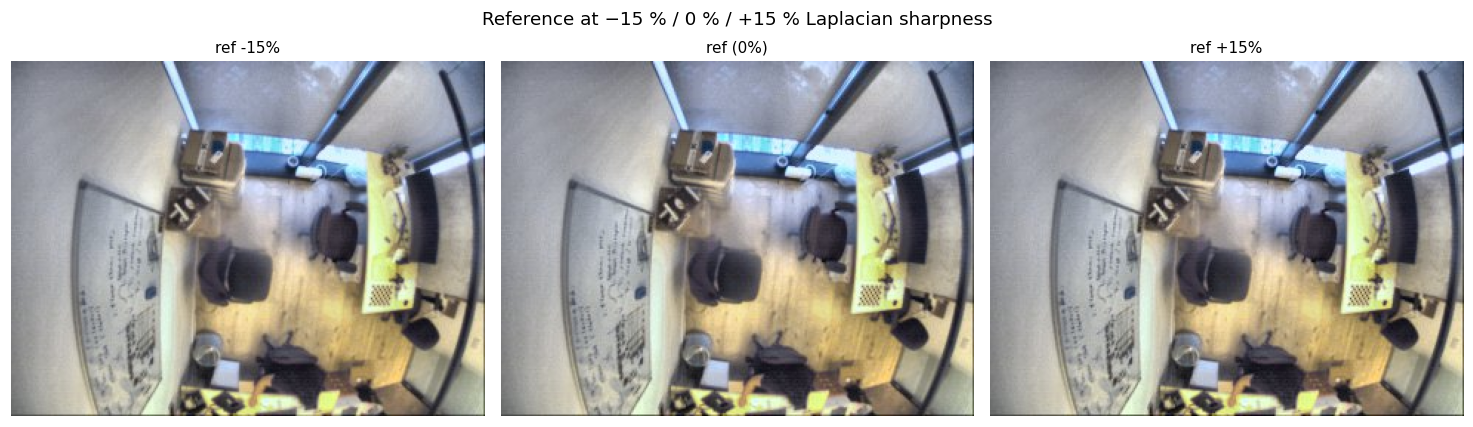

In [7]:
# Visualise the calibrated images at ±15 % and reference.
img_m15, _ = apply_sharpness_change(ref, -15, metric='laplacian')
img_p15, _ = apply_sharpness_change(ref, +15, metric='laplacian')
show_grid(
    {'ref -15%': img_m15, 'ref (0%)': ref, 'ref +15%': img_p15},
    suptitle='Reference at −15 % / 0 % / +15 % Laplacian sharpness',
)

## 6. Production wrapper — `adjust_sharpness`

`find_parameter_for_delta` is O(image size × grid size) per call — too slow for a hot path. `sharpness_tools.CALIBRATION_LAPLACIAN` bakes in the anchor points from section 5 so production code can look up the operator parameter with no per-image optimization. `adjust_sharpness(img, delta_pct)` picks the right operator, interpolates the parameter between the flanking integer anchors, and returns the processed image in a single call.

The same anchors are dumped to [`calibration.csv`](calibration.csv) (both metrics) if the caller prefers a data-file rather than an embedded constant.

Caveat: the anchors were fit on the `6100002` reference. On a very different scene the achieved delta will drift; re-run the calibration pipeline against a new reference and either update `CALIBRATION_LAPLACIAN` or pass a different `table` argument.

In [8]:
import pandas as pd
from sharpness_tools import adjust_sharpness, CALIBRATION_LAPLACIAN

# Inspect the constant
sample_keys = [-15, -10, -5, -1, 0, 1, 5, 10, 15]
pd.DataFrame(
    [{"delta_pct": d, "direction": CALIBRATION_LAPLACIAN[d][0], "param_value": CALIBRATION_LAPLACIAN[d][1]}
     for d in sample_keys],
).set_index('delta_pct')

,direction,param_value
delta_pct,,
-15,soften,0.10020
-10,soften,0.06592
-5,soften,0.03545
-1,soften,0.01318
0,sharpen,0.00000
1,sharpen,0.01289
5,sharpen,0.03340
10,sharpen,0.06270
15,sharpen,0.09199


In [9]:
# End-to-end fidelity: adjust_sharpness on integer and half-integer targets.
verify = []
for d in list(range(-15, 16)) + [-12.5, -7.5, -3.5, 3.5, 7.5, 12.5]:
    out = adjust_sharpness(ref, d)
    achieved = (laplacian_variance(out) - laplacian_variance(ref)) / laplacian_variance(ref) * 100
    verify.append({"target_%": d, "achieved_%": round(achieved, 3), "err_pp": round(achieved - d, 3)})
verify_df = pd.DataFrame(verify).sort_values("target_%").reset_index(drop=True)
verify_df

,target_%,achieved_%,err_pp
0,-15.0,-15.402,-0.402
1,-14.0,-13.997,0.003
2,-13.0,-12.930,0.070
3,-12.5,-12.105,0.395
4,-12.0,-11.905,0.095
5,-11.0,-11.003,-0.003
6,-10.0,-9.909,0.091
7,-9.0,-8.917,0.083
8,-8.0,-7.914,0.086
9,-7.5,-7.555,-0.055


In [10]:
# The same anchors dumped to disk:
import pathlib
csv_df = pd.read_csv(pathlib.Path('calibration.csv'))
print(f'{len(csv_df)} rows, {csv_df.metric.unique().tolist()} metrics')
csv_df.head(6)

62 rows, ['laplacian', 'fft'] metrics


,metric,target_delta_pct,direction,param_name,param_value,kernel_sigma,baseline_sharpness,achieved_sharpness,achieved_delta_pct
0,laplacian,-15,soften,strength,0.10020,1.0,823.604,696.753,-15.402
1,laplacian,-14,soften,strength,0.09375,1.0,823.604,708.321,-13.997
2,laplacian,-13,soften,strength,0.08555,1.0,823.604,717.111,-12.930
3,laplacian,-12,soften,strength,0.07969,1.0,823.604,725.550,-11.905
4,laplacian,-11,soften,strength,0.07148,1.0,823.604,732.982,-11.003
5,laplacian,-10,soften,strength,0.06592,1.0,823.604,741.996,-9.909


## 7. Equalize comparison images to the reference

`equalize_sharpness(src, ref)` picks the right direction (sharpen or soften) and returns an image whose sharpness matches the reference under the chosen metric.

In [11]:
def equalize_all(metric: str) -> tuple[pd.DataFrame, dict[str, np.ndarray]]:
    rows = []
    equalized = {}
    for name, img in cmp_imgs.items():
        out, res = equalize_sharpness(img, ref, metric=metric)
        equalized[name] = out
        rows.append({
            'src': name,
            'metric': metric,
            'ref_sharp':     round(res.ref_sharpness, 2),
            'src_sharp':     round(res.src_sharpness, 2),
            'achieved_sharp': round(res.achieved_sharpness, 2),
            'residual_%':    round((res.achieved_sharpness - res.ref_sharpness) / res.ref_sharpness * 100, 3),
            'direction':     res.calibration.direction,
            'param':         res.calibration.param_name,
            'param_value':   round(res.calibration.param_value, 4),
        })
    return pd.DataFrame(rows), equalized

eq_lap_df, eq_lap_imgs = equalize_all('laplacian')
eq_fft_df, eq_fft_imgs = equalize_all('fft')
print('Equalization by Laplacian variance:')
display(eq_lap_df)
print('Equalization by FFT high-freq energy:')
display(eq_fft_df)

Equalization by Laplacian variance:


,src,metric,ref_sharp,src_sharp,achieved_sharp,residual_%,direction,param,param_value
0,under (6100001),laplacian,823.6,704.41,825.49,0.229,sharpen,amount,0.1002
1,over (6200001),laplacian,823.6,1148.92,824.69,0.132,soften,strength,0.1896


Equalization by FFT high-freq energy:


,src,metric,ref_sharp,src_sharp,achieved_sharp,residual_%,direction,param,param_value
0,under (6100001),fft,2461.51,2195.83,2459.48,-0.082,sharpen,amount,0.1834
1,over (6200001),fft,2461.51,2932.65,2467.01,0.224,soften,strength,0.2473


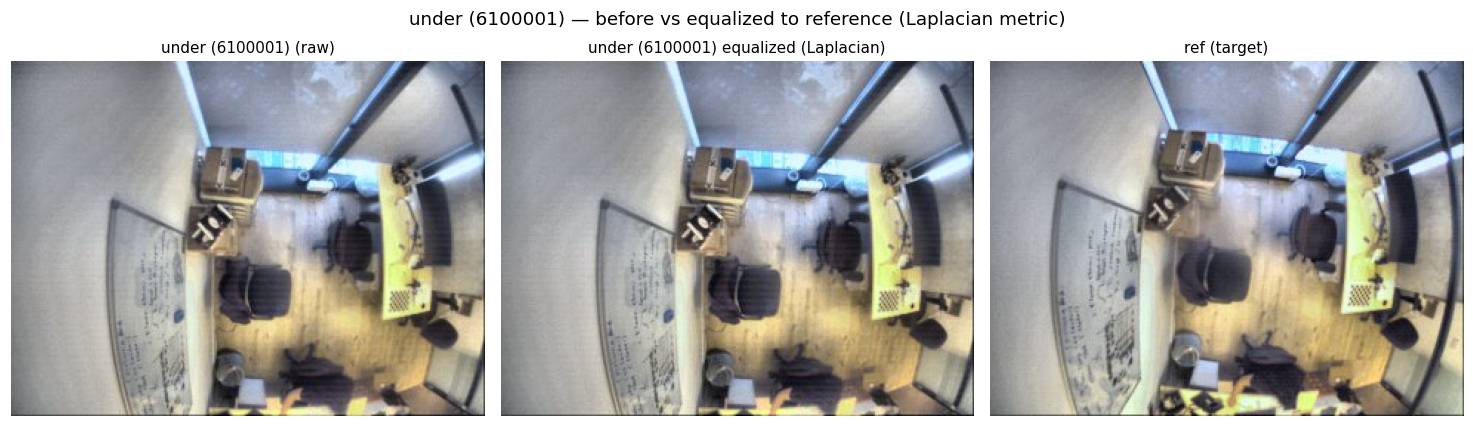

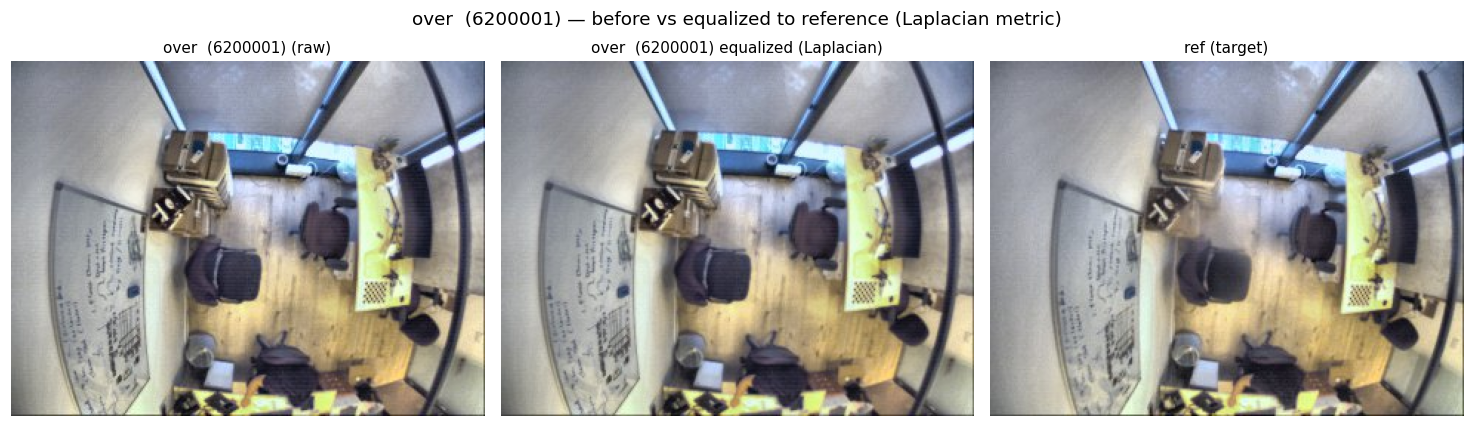

In [12]:
# Original vs equalized-to-ref, side-by-side.
for name, img in cmp_imgs.items():
    show_grid(
        {
            f'{name} (raw)': img,
            f'{name} equalized (Laplacian)': eq_lap_imgs[name],
            'ref (target)': ref,
        },
        suptitle=f'{name} — before vs equalized to reference (Laplacian metric)',
    )

## 8. Cross-check with `camera_qc.metrics.headline_metrics`

Run the QC metric pack over the raw comparison, the equalized-by-Laplacian comparison, and the reference. `sharpness` (Laplacian) should be within a fraction of a percent of the reference; `sharpness_fft` may still differ because we only equalized one of the two.

In [13]:
def qc_row(name: str, img: np.ndarray) -> dict:
    m = headline_metrics(img)
    return {
        'image': name,
        'sharpness (Lap)':  round(m['sharpness'], 2),
        'sharpness_fft':    round(m['sharpness_fft'], 2),
        'noise':            round(m['noise'], 3),
        'L':                round(m['L'], 2),
    }

rows = [qc_row('ref (6100002)', ref)]
for name, img in cmp_imgs.items():
    rows.append(qc_row(f'{name} raw',           img))
    rows.append(qc_row(f'{name} equalized-Lap', eq_lap_imgs[name]))
    rows.append(qc_row(f'{name} equalized-FFT', eq_fft_imgs[name]))
pd.DataFrame(rows).set_index('image')

,sharpness (Lap),sharpness_fft,noise,L
image,,,,
ref (6100002),823.60,2461.51,8.929,149.18
under (6100001) raw,704.41,2195.83,8.217,147.82
under (6100001) equalized-Lap,825.49,2341.74,8.801,147.80
under (6100001) equalized-FFT,930.21,2459.48,9.275,147.78
over (6200001) raw,1148.92,2932.65,10.334,145.86
over (6200001) equalized-Lap,824.69,2567.16,8.982,145.89
over (6200001) equalized-FFT,743.79,2467.01,8.607,145.91


**What the QC table tells us**

- After Laplacian equalization the `sharpness` column agrees with the reference to a fraction of a percent, but `sharpness_fft` is still slightly off.
- After FFT equalization the `sharpness_fft` matches the reference and `sharpness` is only slightly off.
- If both metrics need to match at once, use FFT equalization on the sharper image (the softening operator flattens both bands) or run a second Laplacian pass after FFT equalization — but be aware of the noise floor: extra sharpening always drags `noise` up.
- Luminance `L` is unchanged by the operators; only the sharpness/noise columns move. That means these tools don't help with the color/exposure mismatches; they are *only* a sharpness knob.

## 9. Sanity: known deltas round-trip via calibration

Apply a known delta to the reference, then re-measure and calibrate back. If `apply_sharpness_change` and the metric are internally consistent, this should return the parameter that undoes the previous change with the sign flipped and a residual well under 1 percentage point.

In [14]:
roundtrip = []
for delta_first in [-15, -2, -1, 1, 2, 15]:
    perturbed, cal_first = apply_sharpness_change(ref, delta_first)
    reverse_target = -cal_first.achieved_delta_pct
    _, cal_back = apply_sharpness_change(perturbed, reverse_target)
    final_vs_ref = (cal_back.achieved_sharpness - laplacian_variance(ref)) / laplacian_variance(ref) * 100
    roundtrip.append({
        'first_target_%':  delta_first,
        'first_achieved_%': round(cal_first.achieved_delta_pct, 3),
        'reverse_target_%': round(reverse_target, 3),
        'reverse_achieved_%': round(cal_back.achieved_delta_pct, 3),
        'final_vs_ref_%':  round(final_vs_ref, 3),
    })
pd.DataFrame(roundtrip)

,first_target_%,first_achieved_%,reverse_target_%,reverse_achieved_%,final_vs_ref_%
0,-15,-15.402,15.402,15.345,-2.421
1,-2,-2.042,2.042,1.972,-0.110
2,-1,-0.933,0.933,0.862,-0.080
3,1,0.908,-0.908,-0.848,0.052
4,2,1.955,-1.955,-1.884,0.035
5,15,14.930,-14.930,-14.662,-1.922


**Interpreting the round-trip**

- After a −15 % / +15 % round-trip, we are usually still ~1–3 % off the pristine reference: uint8 quantization is lossy on high-frequency detail, so operators are **not exact inverses**. Softening is especially destructive — once information is blurred out, sharpening only amplifies what remains (including noise).
- Small deltas (±1 – ±2 %) round-trip almost to zero — the corrections are within the operator's precision.
- Practical implication: if you plan to equalize sharpness across a batch, prefer softening the sharpest capture rather than sharpening the softest capture — the sharpen path amplifies noise disproportionately.

## 10. Summary

- The reference `6100002` sits between the two comparison captures. `6100001` is soft (Laplacian −14.5 %, FFT −10.8 %); `6200001` is over-sharp (Laplacian +39.5 %, FFT +19.1 %).
- **For production use**: call `sharpness_tools.adjust_sharpness(img, delta_pct)` — a signed float in `[-15, 15]`. It looks up the operator (sharpen or soften) and parameter from the baked-in `CALIBRATION_LAPLACIAN` constant and returns the processed image; no per-image optimization runs. The same anchors are dumped to [`calibration.csv`](calibration.csv) for language-agnostic access.
- Sharpness deltas of ±1 % … ±15 % on the reference translate to the following operator parameters (Laplacian metric, `kernel_sigma = 1.0`) — see section 5 for the full 30-row table:

  | Δ %  | operator | param value | Δ %  | operator | param value |
  |-----:|:---------|------------:|-----:|:---------|------------:|
  |  +1  | sharpen  |      0.013  |  −1  | soften   |      0.013  |
  |  +5  | sharpen  |      0.033  |  −5  | soften   |      0.035  |
  | +10  | sharpen  |      0.063  | −10  | soften   |      0.066  |
  | +15  | sharpen  |      0.092  | −15  | soften   |      0.100  |

- Rule of thumb (Laplacian metric on this reference): `amount ≈ 0.006 · Δ%` for sharpen, `strength ≈ 0.007 · Δ%` for soften over the ±15 % range. Both stay roughly linear because we're far from clipping. Above ~20 % the sharpen response starts to bend (edges saturate); below −20 % the soften response starts to lose contrast globally.
- Equalizing to the reference (Laplacian metric):
  - `6100001` (under) → `sharpen(amount ≈ 0.10, sigma=1.0)`  (or `adjust_sharpness(img, +17)` if you extend the calibration range)
  - `6200001` (over)  → `soften(strength ≈ 0.19, sigma=1.0)`  (or `adjust_sharpness(img, -28)` if the range is extended)
- The FFT metric is more forgiving of noise but disagrees with Laplacian on the exact operator parameter (needs roughly 2× larger parameters for the same delta). Choose whichever metric matches the acceptance criterion of the downstream QC step (`camera_qc` uses both, so tune to whichever is failing). `calibration.csv` carries anchors for both metrics.
- Noise couples strongly to sharpness. Report both when you tune.
- The lookup was fit against the specific reference `6100002-2000-000008-2550.jpg`. On dramatically different scenes the achieved delta will drift by 1 – 3 pp; re-run `find_parameter_for_delta` and update `CALIBRATION_LAPLACIAN` (or pass a custom `table` to `adjust_sharpness`) if that precision matters.